In [2]:
import io, os, subprocess, sys
import pandas as pd
import matplotlib.pyplot as plt

DATA = os.path.expanduser("~/311_2024.csv")
TOP = "illegal parking"

def run_cli(start, end):
    out = subprocess.run(
        [sys.executable, "borough_complaints.py", "-i", DATA, "-s", start, "-e", end],
        capture_output=True, text=True, check=True).stdout
    return pd.read_csv(io.StringIO(out), skipinitialspace=True)

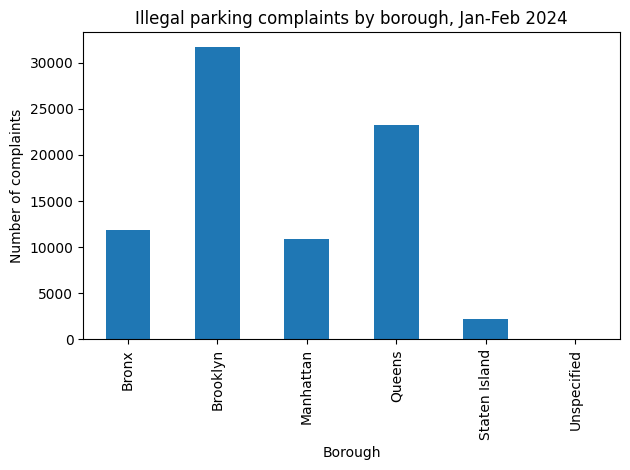

borough
Bronx            11836
Brooklyn         31702
Manhattan        10872
Queens           23255
Staten Island     2245
Unspecified          6
Name: count, dtype: int64 
Total: 79916


In [3]:
early = run_cli("2024-01-01", "2024-02-29")
e = early[early["complaint type"] == TOP].set_index("borough")["count"]
ax = e.plot(kind="bar", title="Illegal parking complaints by borough, Jan-Feb 2024")
ax.set_xlabel("Borough"); ax.set_ylabel("Number of complaints")
plt.tight_layout(); plt.show()
print(e, "\nTotal:", e.sum())

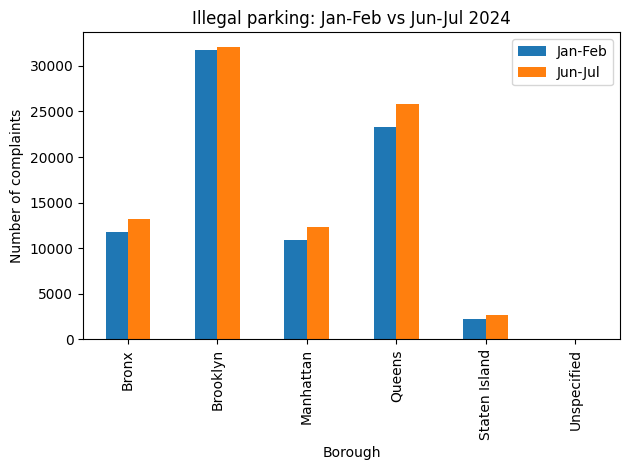

               Jan-Feb  Jun-Jul
borough                        
Bronx            11836    13189
Brooklyn         31702    32077
Manhattan        10872    12366
Queens           23255    25861
Staten Island     2245     2734
Unspecified          6       10 
Totals:
 Jan-Feb    79916
Jun-Jul    86237
dtype: int64


In [4]:
summer = run_cli("2024-06-01", "2024-07-31")
s = summer[summer["complaint type"] == TOP].set_index("borough")["count"]
cmp = pd.DataFrame({"Jan-Feb": e, "Jun-Jul": s})
ax = cmp.plot(kind="bar", title="Illegal parking: Jan-Feb vs Jun-Jul 2024")
ax.set_xlabel("Borough"); ax.set_ylabel("Number of complaints")
plt.tight_layout(); plt.show()
print(cmp, "\nTotals:\n", cmp.sum())